# Phase 4: Clustering (data mining)

**Goal:** describe each team-season's **playing style per phase of play**, as football analysis does: how it
**attacks** (in possession) and how it **defends** (out of possession) (Fernandez-Navarro et al. 2016; Demir et al.).
Each phase is clustered with **K-means** on its four dimensions from Phase 3 (k chosen by elbow, silhouette,
Davies–Bouldin, Calinski–Harabasz, stability and interpretability) and compared with **hierarchical clustering
(Ward)**. A team-season's style is the pair, e.g. *Positional possession · High press, high line*. Formation (back
three) is reported per style, not clustered. Team strength and workload are shown, not clustered.

**Steps**
1. Phase dimensions
2. K-means for k = 2…10 per phase: quality measures, stability (bootstrap ARI and per-cluster Jaccard), Ward
3. Profiles at k = 4 per phase: centroids, typical teams, strength, workload, formation, leagues
4. Names (by rule) and the combined style; saved clusters
5. Soft memberships (Gaussian mixture) and consensus clustering
6. Sensitivity clusterings: k = 3, and style relative to the league-season
7. How the attacking and defensive styles combine
8. 2-D views (PCA, for visualisation only)
9. Report

**Input:** `data/03_features/` (phase dimensions, features), `us_team_matches` (points, strength check only).
**Outputs:** `data/04_clusters/`, `reports/04_clustering.md`, `reports/figures/04_*.png`.

In [1]:
import sys
from datetime import date
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from scipy.cluster.hierarchy import fcluster
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import squareform

sys.path.insert(0, str(Path.cwd().parent))  # project root, for the analysis package
from analysis.config import DATA_DIR, FIGURES_DIR, REPORTS_DIR, phase_dir
from analysis.load import league_from_understat, read_table
from analysis.report import md_table

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 140)

PHASE = "04_clusters"
OUT_DIR = phase_dir(PHASE)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
K_RANGE = range(2, 11)
N_INIT = 50  # K-means restarts per fit; the best (lowest inertia) is kept
N_BOOT = 50  # bootstrap resamples for stability
MIN_JACCARD = 0.6  # every cluster's mean bootstrap Jaccard at least this (Hennig 2007)
MIN_SHARE = 0.03  # no cluster smaller than 3% of team-seasons
MAIN_K = {"attack": 4, "defence": 4}  # agreed with the user after reading step 2 (see DECISIONS.md)
RARE_COMBINATION = 40  # combined styles with fewer team-seasons are flagged as rare
PHASES = ["attack", "defence"]

# Chart palette: validated reference palette (dataviz skill), categorical slots in fixed order.
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2,
})


def save(fig, name: str) -> str:
    path = FIGURES_DIR / name
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))
    return name

## Step 1. Phase dimensions

Four attacking (possession, patience, verticality, directness) and four defensive (press, high line, territory
conceded, aggression) dimensions from Phase 3, each standardised.

In [2]:
style_dims = pd.read_parquet(DATA_DIR / "03_features" / "style_dimensions.parquet")
features = pd.read_parquet(DATA_DIR / "03_features" / "team_season_features.parquet")
assert (style_dims[["season", "tm_club_id"]].to_numpy() == features[["season", "tm_club_id"]].to_numpy()).all()
DIMS = {ph: [c for c in style_dims.columns if c.startswith(f"{ph}_")] for ph in PHASES}
X = {ph: style_dims[cols].to_numpy() for ph, cols in DIMS.items()}
assert not any(np.isnan(x).any() for x in X.values())
style_dims[DIMS["attack"] + DIMS["defence"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
attack_possession,1170.0,0.0,1.0,-1.84,-0.72,-0.25,0.52,4.64
attack_patience,1170.0,0.0,1.0,-2.19,-0.72,-0.10,0.58,5.83
attack_verticality,1170.0,-0.0,1.0,-2.46,-0.71,-0.09,0.64,3.64
attack_directness,1170.0,0.0,1.0,-2.77,-0.72,0.01,0.69,3.22
defence_press,1170.0,0.0,1.0,-3.52,-0.67,0.08,0.75,2.33
defence_high_line,1170.0,-0.0,1.0,-2.35,-0.69,-0.07,0.60,6.44
defence_territory_conceded,1170.0,0.0,1.0,-3.03,-0.72,0.01,0.70,2.88
defence_aggression,1170.0,-0.0,1.0,-2.52,-0.68,-0.04,0.62,3.50


## Step 2. Choosing k per phase

For each phase and k: K-means with 50 starts (fixed seed), inertia (elbow), silhouette (higher better),
Davies–Bouldin (lower better), Calinski–Harabasz (higher better); **stability** by refitting on 50 bootstrap samples:
overall adjusted Rand index (ARI) and the **per-cluster Jaccard** (Hennig 2007: < 0.5 dissolves, ≥ 0.6 a pattern,
≥ 0.75 stable); and agreement with **Ward** (ARI). A k is usable when every cluster reaches Jaccard 0.6 and none is
under 3% of team-seasons.

In [3]:
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(style_dims), len(style_dims)) for _ in range(N_BOOT)]
kmeans, summary_rows, jaccard = {}, [], {}


def bootstrap(x: np.ndarray, ref: np.ndarray, k: int) -> tuple[list[float], np.ndarray]:
    aris, jac = [], np.zeros((N_BOOT, k))
    for b, idx in enumerate(boot_idx):
        fit = KMeans(n_clusters=k, n_init=10, random_state=SEED + b).fit(x[idx])
        aris.append(adjusted_rand_score(ref, fit.predict(x)))
        inside = np.unique(idx)
        both = np.zeros((k, k))
        np.add.at(both, (ref[inside], fit.predict(x[inside])), 1)
        jac[b] = (both / (both.sum(axis=1, keepdims=True) + both.sum(axis=0, keepdims=True) - both)).max(axis=1)
    return aris, jac.mean(axis=0)


for ph, x in X.items():
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(x)
        kmeans[(ph, k)] = km
        aris, jac = bootstrap(x, km.labels_, k)
        jaccard[(ph, k)] = jac
        ward = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(x)
        summary_rows.append({
            "phase": ph, "k": k, "inertia": km.inertia_, "silhouette": silhouette_score(x, km.labels_),
            "davies_bouldin": davies_bouldin_score(x, km.labels_), "calinski_harabasz": calinski_harabasz_score(x, km.labels_),
            "stability (mean ARI)": np.mean(aris), "min cluster Jaccard": jac.min(),
            "Ward vs K-means (ARI)": adjusted_rand_score(km.labels_, ward), "smallest cluster": np.bincount(km.labels_).min(),
        })
summary = pd.DataFrame(summary_rows)
summary["usable"] = (summary["min cluster Jaccard"] >= MIN_JACCARD) & (summary["smallest cluster"] >= MIN_SHARE * len(style_dims)) & (summary.k >= 3)
for ph in PHASES:
    assert summary.query("phase == @ph and k == @MAIN_K[@ph]").usable.all(), f"k = {MAIN_K[ph]} not usable for {ph}"
summary.round(3)

,phase,k,inertia,silhouette,davies_bouldin,calinski_harabasz,stability (mean ARI),min cluster Jaccard,Ward vs K-means (ARI),smallest cluster,usable
0,attack,2,3098.521,0.316,1.246,596.165,0.878,0.917,0.554,388,False
1,attack,3,2536.576,0.241,1.364,493.061,0.841,0.876,0.425,341,True
2,attack,4,2194.689,0.217,1.341,440.134,0.634,0.637,0.394,174,True
3,attack,5,1987.285,0.208,1.356,394.635,0.587,0.532,0.337,131,False
4,attack,6,1822.033,0.201,1.374,365.161,0.576,0.560,0.403,84,False
5,attack,7,1687.996,0.199,1.331,343.575,0.558,0.525,0.365,66,False
6,attack,8,1569.915,0.202,1.290,328.855,0.639,0.583,0.363,61,False
7,attack,9,1480.451,0.197,1.290,313.644,0.597,0.520,0.323,49,False
8,attack,10,1409.563,0.192,1.322,299.045,0.539,0.463,0.323,46,False
9,defence,2,3308.096,0.258,1.432,484.383,0.918,0.958,0.302,568,False


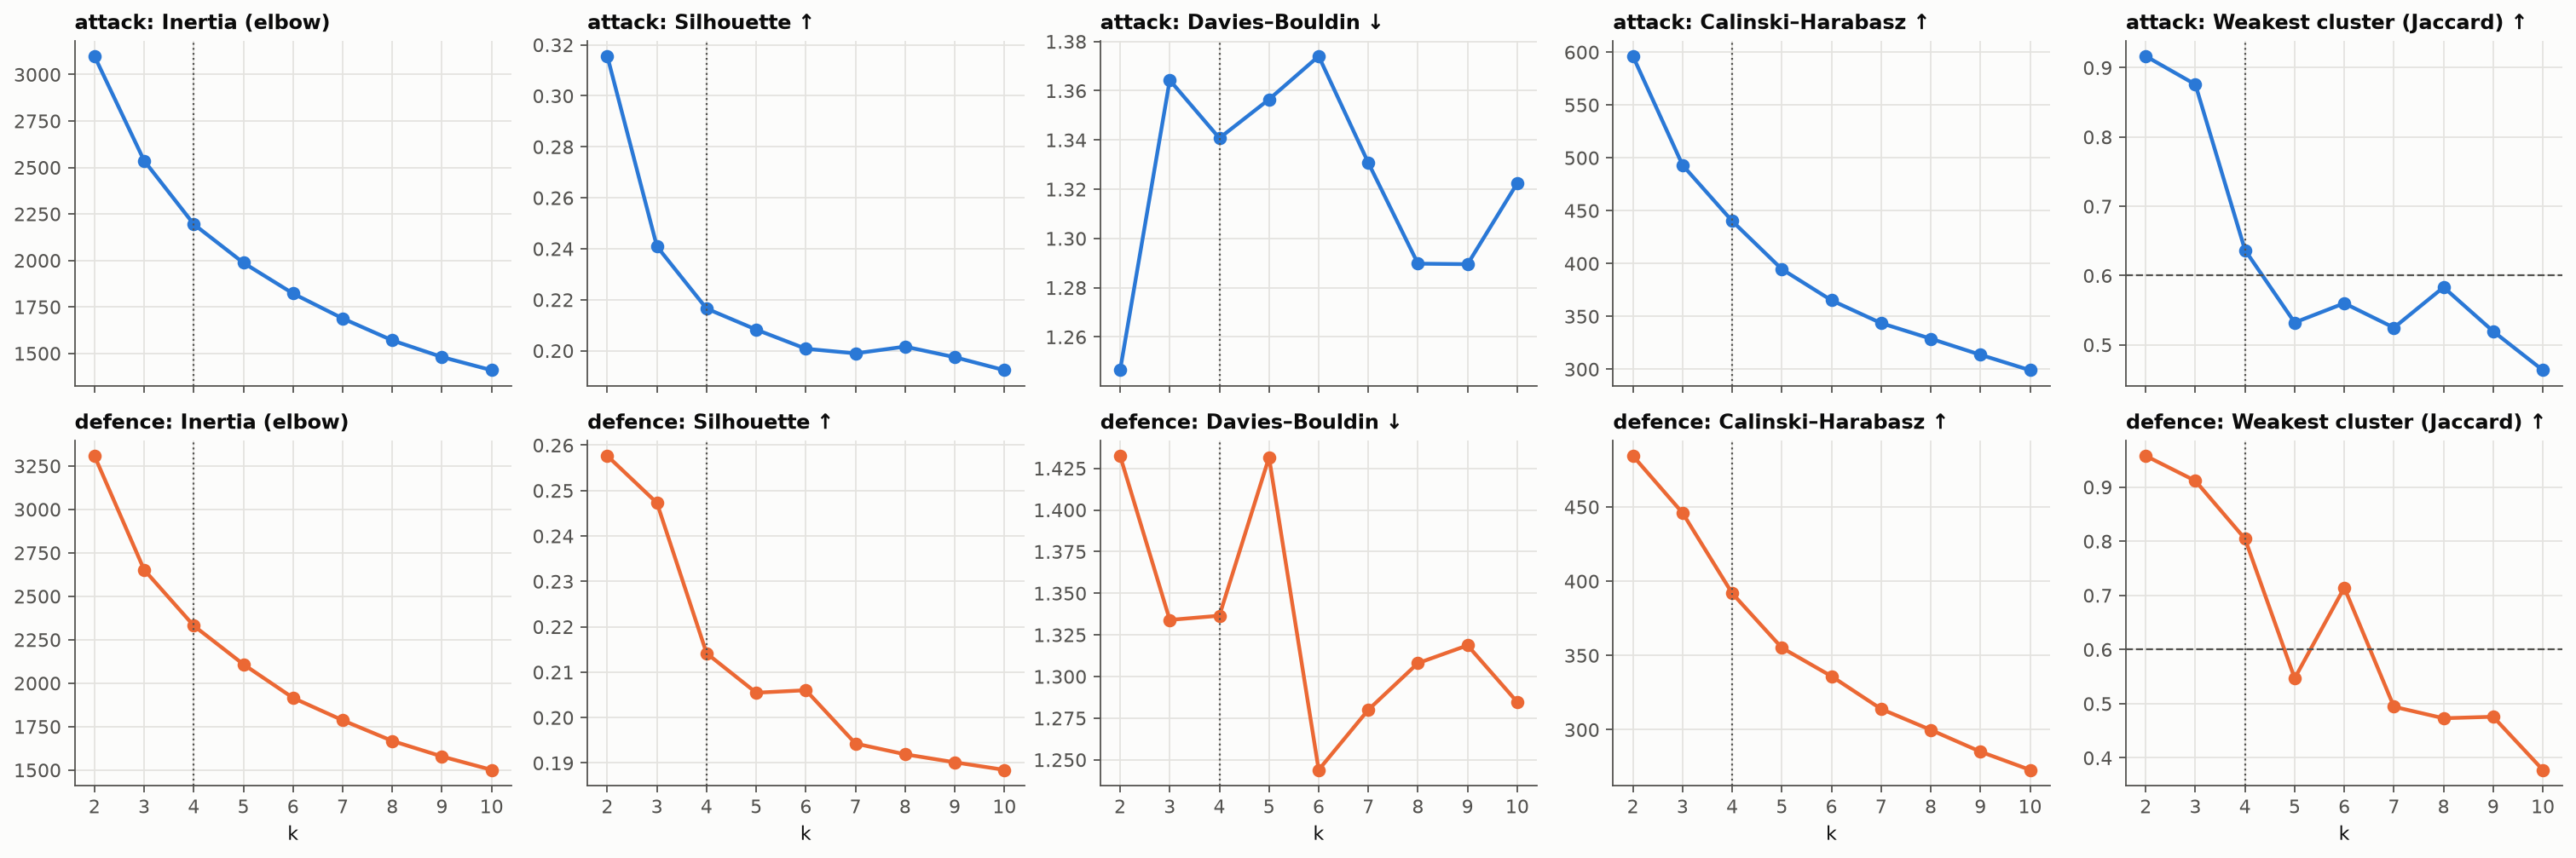

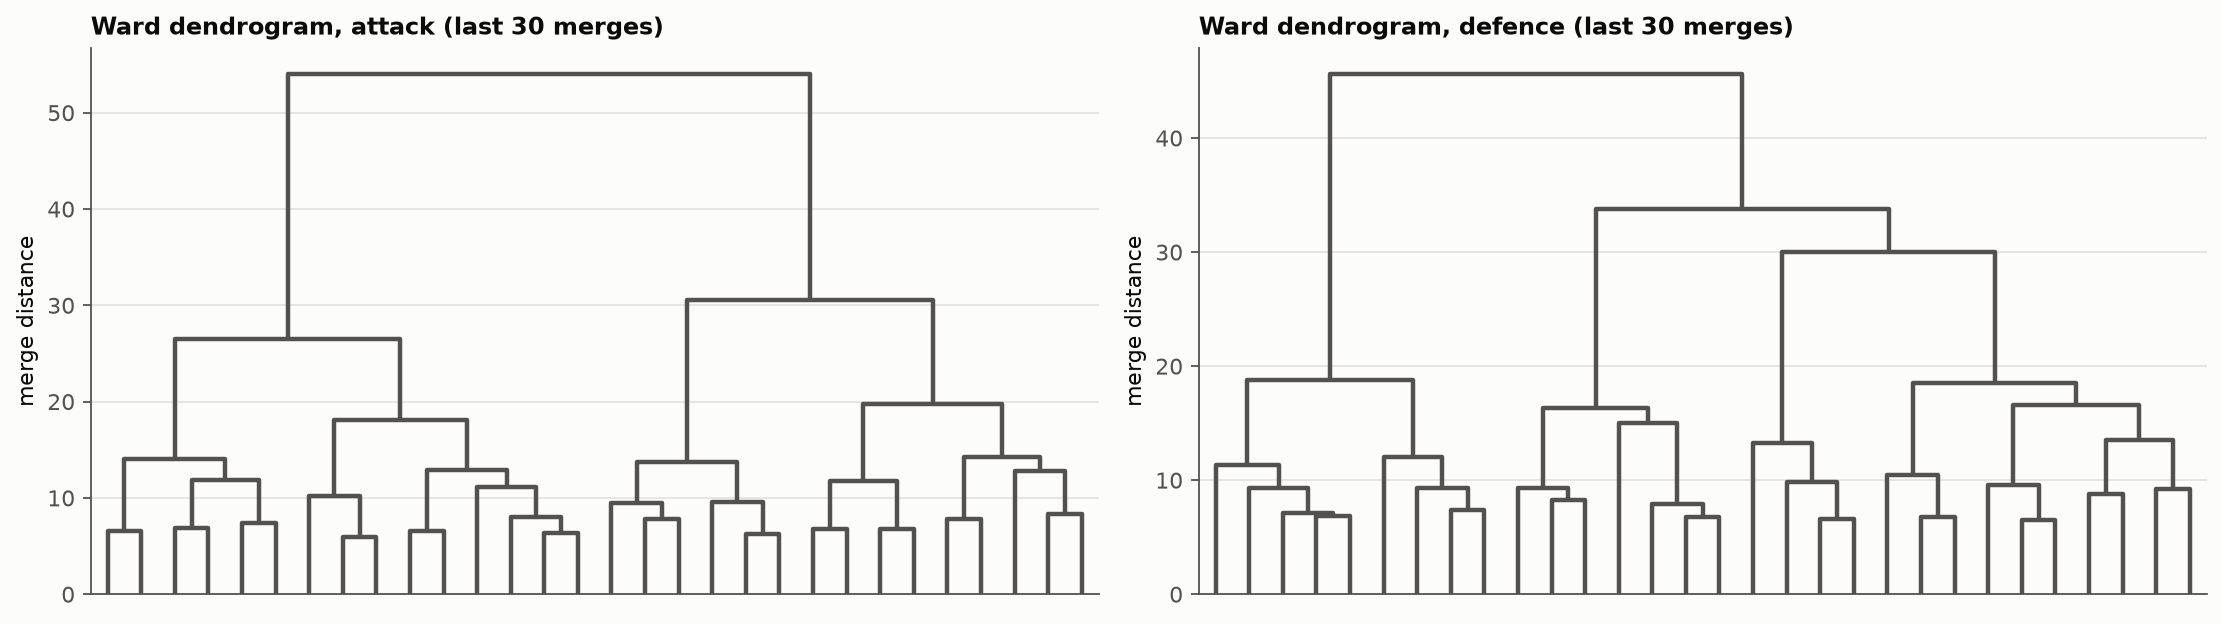

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(19, 6.4), sharex=True)
measures = [("inertia", "Inertia (elbow)"), ("silhouette", "Silhouette ↑"), ("davies_bouldin", "Davies–Bouldin ↓"),
            ("calinski_harabasz", "Calinski–Harabasz ↑"), ("min cluster Jaccard", "Weakest cluster (Jaccard) ↑")]
for row, ph in enumerate(PHASES):
    d = summary[summary.phase == ph]
    for ax, (col, title) in zip(axes[row], measures):
        ax.plot(d.k, d[col], color=SERIES[row], marker="o", markersize=6)
        ax.axvline(MAIN_K[ph], color=MUTED, linewidth=1, linestyle=":")
        ax.set_title(f"{ph}: {title}", loc="left")
        ax.set_xticks(list(K_RANGE))
    axes[row, 4].axhline(MIN_JACCARD, color=MUTED, linewidth=1, linestyle="--")
for ax in axes[1]:
    ax.set_xlabel("k")
fig.tight_layout()
quality_fig = save(fig, "04_k_selection.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, ph in zip(axes, PHASES):
    dendrogram(linkage(X[ph], method="ward"), truncate_mode="lastp", p=30, ax=ax, color_threshold=0,
               above_threshold_color=MUTED, no_labels=True)
    ax.set_title(f"Ward dendrogram, {ph} (last 30 merges)", loc="left")
    ax.set_ylabel("merge distance")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
dendro_fig = save(fig, "04_dendrograms.png")

## Step 3. Profiles at k = 4 per phase

For each phase: centroids, per-cluster stability, the team-seasons closest to each centroid, team strength (points
and npxG per match), workload, the share of minutes in a back three and the league mix.

In [5]:
um = read_table("us_team_matches")
points = (um.assign(league=um.league.map(league_from_understat), season=um.season.astype(int), pts=um.pts.astype(float))
          .groupby(["league", "season", "team_id"]).pts.mean().rename("points_pm").reset_index().rename(columns={"team_id": "us_team_id"}))
keys = pd.read_csv(DATA_DIR / "01_entities" / "team_seasons.csv", dtype={"tm_club_id": str, "us_team_id": str})
roles = pd.read_csv(DATA_DIR / "03_features" / "feature_roles.csv")
EXPOSURE = roles[(roles.role == "exposure") & (roles.status == "kept")].feature.tolist()
base = (features.drop(columns="back_three_share").join(style_dims.drop(columns=["league", "season", "season_key", "tm_club_id", "club"]))
        .merge(keys[["league", "season", "tm_club_id", "us_team_id"]], on=["league", "season", "tm_club_id"])
        .merge(points, on=["league", "season", "us_team_id"], how="left"))
assert base.points_pm.notna().all() and len(base) == len(style_dims)


def eta_squared(values: pd.Series, groups: pd.Series) -> float:
    grand = values.mean()
    between = sum(len(v) * (v.mean() - grand) ** 2 for _, v in values.groupby(groups))
    return between / ((values - grand) ** 2).sum()


profiles = {}
for ph in PHASES:
    k, km = MAIN_K[ph], kmeans[(ph, MAIN_K[ph])]
    df = base.assign(cluster=km.labels_ + 1)
    dist = np.linalg.norm(X[ph] - km.cluster_centers_[km.labels_], axis=1)
    g = df.groupby("cluster")
    profiles[ph] = {
        "df": df,
        "centroid": g[DIMS[ph]].mean().rename(columns=lambda c: c.split("_", 1)[1]),
        "context": pd.concat([g.size().rename("n"), pd.Series(jaccard[(ph, k)].round(2), index=range(1, k + 1), name="Jaccard"),
                              g.points_pm.mean().round(2).rename("points/match"), g.npxg_pm.mean().round(2).rename("npxG/match"),
                              g.back_three_share.mean().round(2).rename("back-three minutes"), g[EXPOSURE].mean().round(2)], axis=1),
        "examples": (df.assign(dist=dist).sort_values("dist").groupby("cluster").head(4)
                     .assign(team=lambda d: d.club + " " + d.season_key).groupby("cluster").team.apply(", ".join)),
        "leagues": pd.crosstab(df.cluster, df.league, normalize="index").round(2),
        "eta2_points": eta_squared(df.points_pm, df.cluster),
    }
for ph, p in profiles.items():
    print(f"\n==================== {ph}, k = {MAIN_K[ph]} (points eta² = {p['eta2_points']:.2f}) ====================")
    display(p["centroid"].round(2))
    display(pd.concat([p["context"], p["examples"].rename("closest to centroid")], axis=1))
    display(p["leagues"])


==================== attack, k = 4 (points eta² = 0.39) ====================


,possession,patience,verticality,directness
cluster,,,,
1,-0.53,-0.28,-0.57,0.83
2,1.62,1.41,-0.80,-0.97
3,-0.64,-0.71,1.17,0.45
4,0.25,0.16,0.05,-0.73


,n,Jaccard,points/match,npxG/match,back-three minutes,matches_all,matches_europe,short_rest_share,rest_sd,top14_share,closest to centroid
1,362,0.72,1.15,1.05,0.22,42.23,1.55,0.18,3.28,0.79,"Swansea City 2014-15, AS Saint-Étienne 2020-21, Arminia Bielefeld 2021-22, Genoa CFC 2023-24"
2,174,0.80,1.96,1.80,0.23,51.66,9.21,0.29,3.09,0.81,"Borussia Dortmund 2022-23, Atalanta BC 2021-22, SSC Napoli 2022-23, Real Madrid 2023-24"
3,279,0.71,1.16,1.09,0.18,41.87,1.50,0.17,3.28,0.80,"Cagliari Calcio 2023-24, Rayo Vallecano 2014-15, Burnley FC 2019-20, Dijon FCO 2019-20"
4,355,0.64,1.48,1.41,0.29,45.97,4.86,0.23,3.19,0.81,"TSG 1899 Hoffenheim 2023-24, Borussia Mönchengladbach 2017-18, LOSC Lille 2021-22, Olympique Marseille 2016-17"


league,Bundesliga,La Liga,Ligue 1,Premier League,Serie A
cluster,,,,,
1,0.15,0.20,0.23,0.17,0.25
2,0.14,0.14,0.17,0.30,0.25
3,0.23,0.24,0.20,0.17,0.15
4,0.21,0.21,0.18,0.22,0.18



==================== defence, k = 4 (points eta² = 0.34) ====================


,press,high_line,territory_conceded,aggression
cluster,,,,
1,-0.03,-0.66,-0.49,-0.20
2,0.81,1.09,-0.93,-0.67
3,-1.04,-0.32,1.01,-0.38
4,0.60,0.13,0.06,1.24


,n,Jaccard,points/match,npxG/match,back-three minutes,matches_all,matches_europe,short_rest_share,rest_sd,top14_share,closest to centroid
1,289,0.80,1.55,1.34,0.27,46.32,5.11,0.23,3.18,0.81,"Atlético de Madrid 2025-26, SV Werder Bremen 2017-18, Borussia Mönchengladbach 2019-20, Stade Rennais FC 2023-24"
2,245,0.86,1.76,1.64,0.18,49.60,7.53,0.27,3.15,0.81,"Stade Rennais FC 2016-17, Real Sociedad 2017-18, Atalanta BC 2018-19, Juventus FC 2024-25"
3,350,0.91,1.07,1.11,0.27,41.28,1.08,0.16,3.25,0.80,"US Cremonese 2022-23, Girona FC 2025-26, AJ Auxerre 2024-25, OGC Nice 2025-26"
4,286,0.91,1.23,1.13,0.20,42.96,2.13,0.19,3.30,0.79,"Real Betis Balompié 2019-20, Inter Milan 2015-16, Deportivo Alavés 2025-26, SV Werder Bremen 2015-16"


league,Bundesliga,La Liga,Ligue 1,Premier League,Serie A
cluster,,,,,
1,0.13,0.22,0.31,0.13,0.21
2,0.22,0.13,0.25,0.28,0.12
3,0.24,0.05,0.15,0.36,0.20
4,0.14,0.44,0.10,0.03,0.29


## Step 4. Names and the combined style

Names come from football analysis vocabulary and are given **by rule** (applied in order, each picking among the
clusters not yet named), so they stay with the right cluster if K-means numbers them differently.

| Phase | Name | Rule | Meaning |
|---|---|---|---|
| attack | Positional possession | highest possession | dominates the ball, patient build-up |
| attack | Counter-attack | highest verticality | little of the ball, fast vertical attacks |
| attack | Direct play | highest directness | long-range shots and set plays, low possession |
| attack | Build-up into the box | the rest | moderate possession, works the ball into the box |
| defence | High press, high line | highest high line | presses high, line exposed to counters |
| defence | Low block | most territory conceded | sits deep, lets the opponent near the box |
| defence | Aggressive duel press | highest aggression | presses through fouls and duels |
| defence | Compact mid-block | the rest | medium press, low line, concedes little |

In [6]:
NAMING = {
    "attack": [("Positional possession", "possession", "max"), ("Counter-attack", "verticality", "max"),
               ("Direct play", "directness", "max"), ("Build-up into the box", None, None)],
    "defence": [("High press, high line", "high_line", "max"), ("Low block", "territory_conceded", "max"),
                ("Aggressive duel press", "aggression", "max"), ("Compact mid-block", None, None)],
}


def name_clusters(centroids: pd.DataFrame, rules: list) -> dict[int, str]:
    remaining, names = list(centroids.index), {}
    for name, dim, how in rules:
        if dim is None:
            assert len(remaining) == 1
            pick = remaining[0]
        else:
            col = centroids.loc[remaining, dim]
            pick = col.idxmax() if how == "max" else col.idxmin()
        names[pick] = name
        remaining.remove(pick)
    return names


NAMES = {ph: name_clusters(profiles[ph]["centroid"], NAMING[ph]) for ph in PHASES}
ORDER = {ph: [n for n, _, _ in NAMING[ph]] for ph in PHASES}
out = base[["league", "season", "season_key", "tm_club_id", "club", "back_three_share"]].assign(
    attack_cluster=profiles["attack"]["df"].cluster, attack_style=profiles["attack"]["df"].cluster.map(NAMES["attack"]),
    defence_cluster=profiles["defence"]["df"].cluster, defence_style=profiles["defence"]["df"].cluster.map(NAMES["defence"]))
out["style"] = out.attack_style + " · " + out.defence_style
counts = out["style"].value_counts()
out["rare_style"] = out["style"].map(counts) < RARE_COMBINATION
out["back_three"] = out.back_three_share >= 0.5
assert out.notna().all().all()
out.to_parquet(OUT_DIR / "team_season_clusters.parquet", index=False)
summary.to_csv(OUT_DIR / "k_selection.csv", index=False)
for ph in PHASES:
    display(pd.Series(NAMES[ph], name=f"{ph} style").to_frame())
print(f"saved {len(out)} team-seasons; {(~out.rare_style).sum()} in {counts[counts >= RARE_COMBINATION].size} combined styles "
      f"with ≥ {RARE_COMBINATION} team-seasons, {out.rare_style.sum()} in rare ones")

,attack style
2,Positional possession
3,Counter-attack
1,Direct play
4,Build-up into the box


,defence style
2,"High press, high line"
3,Low block
4,Aggressive duel press
1,Compact mid-block


saved 1170 team-seasons; 1132 in 13 combined styles with ≥ 40 team-seasons, 38 in rare ones


## Step 5. Soft memberships (Gaussian mixture) and consensus clustering

K-means gives every team-season one style, but many sit between two. Two further clustering methods, both still
clustering, check and refine that:
- **Gaussian mixture model (GMM)** per phase, k = 2…10 (full covariance, 10 starts, fixed seed): its BIC is a
  model-based second opinion on k, and at k = 4 it gives each team-season a **membership probability** for every
  style. Its groups only partly match K-means, so it serves as a robustness check, not as the membership measure.
- **Fuzzy membership** (fuzzy c-means memberships from the K-means centroids, fuzziness m = 2; Bezdek 1981): each
  team-season's degree of belonging (0–1, summing to 1) to every style, consistent with the K-means clusters. A
  team-season with membership ≥ 0.5 in its own style is a **clear member** (used in Phase 5); its second style and
  membership show what it borders on.
- **Consensus clustering**: 50 bootstrap K-means fits, 50 bootstrap GMM fits and Ward are combined into how often each
  pair of team-seasons ends up together (co-association), and that matrix is clustered (average linkage, k = 4).

K-means stays the main assignment. Ward and GMM are the **independent** checks (different methods); the consensus is
built half from bootstrap K-means, so its high agreement with K-means is expected: it is a **stability summary**, not
an independent validation.

In [7]:
def align(reference: np.ndarray, labels: np.ndarray, k: int) -> np.ndarray:
    """Relabel `labels` (0..k-1) to the K-means cluster (0..k-1) they overlap most, one-to-one."""
    both = np.zeros((k, k))
    np.add.at(both, (labels, reference), 1)
    rows, cols = linear_sum_assignment(-both)
    return dict(zip(rows, cols))


gmm_rows, soft = [], {}
for ph in PHASES:
    x, k = X[ph], MAIN_K[ph]
    for kk in K_RANGE:
        g = GaussianMixture(kk, covariance_type="full", n_init=10, random_state=SEED).fit(x)
        gmm_rows.append({"phase": ph, "k": kk, "BIC": g.bic(x), "AIC": g.aic(x),
                         "GMM vs K-means (ARI)": adjusted_rand_score(kmeans[(ph, kk)].labels_, g.predict(x))})
    ref = kmeans[(ph, k)].labels_
    g = GaussianMixture(k, covariance_type="full", n_init=10, random_state=SEED).fit(x)
    mapping = align(ref, g.predict(x), k)
    proba = np.zeros((len(x), k))
    for comp, cl in mapping.items():
        proba[:, cl] = g.predict_proba(x)[:, comp]
    # Consensus: co-association over bootstrap K-means, bootstrap GMM and Ward partitions of all team-seasons.
    co, parts = np.zeros((len(x), len(x))), 0
    for b, idx in enumerate(boot_idx):
        for model in (KMeans(n_clusters=k, n_init=10, random_state=SEED + b), GaussianMixture(k, n_init=3, random_state=SEED + b)):
            lab = model.fit(x[idx]).predict(x)
            co += lab[:, None] == lab[None, :]
            parts += 1
    ward_lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(x)
    co += ward_lab[:, None] == ward_lab[None, :]
    co /= parts + 1
    cons = fcluster(linkage(squareform(1 - co, checks=False), method="average"), k, criterion="maxclust") - 1
    cmap = align(ref, cons, k)
    soft[ph] = {"proba": proba, "gmm": np.array([mapping[c] for c in g.predict(x)]), "consensus": np.array([cmap[c] for c in cons])}
gmm_summary = pd.DataFrame(gmm_rows)
agreement = pd.DataFrame([{
    "phase": ph, "K-means vs Ward (ARI)": summary.query("phase == @ph and k == @MAIN_K[@ph]")["Ward vs K-means (ARI)"].iloc[0],
    "K-means vs GMM (ARI)": adjusted_rand_score(kmeans[(ph, MAIN_K[ph])].labels_, soft[ph]["gmm"]),
    "K-means vs consensus (ARI)": adjusted_rand_score(kmeans[(ph, MAIN_K[ph])].labels_, soft[ph]["consensus"]),
    "same style as GMM": (kmeans[(ph, MAIN_K[ph])].labels_ == soft[ph]["gmm"]).mean(),
    "same style as consensus": (kmeans[(ph, MAIN_K[ph])].labels_ == soft[ph]["consensus"]).mean(),
    "clear members (GMM p ≥ 0.8)": (soft[ph]["proba"][np.arange(len(style_dims)), kmeans[(ph, MAIN_K[ph])].labels_] >= 0.8).mean(),
    "lowest-BIC k": int(gmm_summary[gmm_summary.phase == ph].sort_values("BIC").k.iloc[0]),
} for ph in PHASES]).set_index("phase")

for ph in PHASES:
    lab = kmeans[(ph, MAIN_K[ph])].labels_
    out[f"{ph}_gmm_p"] = soft[ph]["proba"][np.arange(len(out)), lab].round(3)
    out[f"{ph}_gmm_style"] = pd.Series(soft[ph]["gmm"] + 1).map(NAMES[ph]).to_numpy()
    out[f"{ph}_consensus_style"] = pd.Series(soft[ph]["consensus"] + 1).map(NAMES[ph]).to_numpy()
FUZZY_M = 2  # fuzziness of the memberships (the conventional value)
for ph in PHASES:
    km, x = kmeans[(ph, MAIN_K[ph])], X[ph]
    dist = np.linalg.norm(x[:, None, :] - km.cluster_centers_[None, :, :], axis=2) + 1e-12
    member = 1 / ((dist[:, :, None] / dist[:, None, :]) ** (2 / (FUZZY_M - 1))).sum(axis=2)
    rows = np.arange(len(x))
    second = np.argsort(-member, axis=1)[:, 1]
    out[f"{ph}_membership"] = member[rows, km.labels_].round(3)
    out[f"{ph}_second_style"] = pd.Series(second + 1).map(NAMES[ph]).to_numpy()
    out[f"{ph}_second_membership"] = member[rows, second].round(3)
    assert np.allclose(member.sum(axis=1), 1) and (member.argmax(axis=1) == km.labels_).all()
assert out.notna().all().all()
out.to_parquet(OUT_DIR / "team_season_clusters.parquet", index=False)
gmm_summary.to_csv(OUT_DIR / "gmm_selection.csv", index=False)
display(gmm_summary.pivot(index="k", columns="phase", values=["BIC", "GMM vs K-means (ARI)"]).round(3))
agreement.round(3).T

BIC            GMM vs K-means (ARI)        
phase     attack    defence               attack defence
k                                                       
2      12181.237  12499.464                0.719   0.640
3      12244.606  12541.842                0.636   0.642
4      12302.831  12604.750                0.302   0.544
5      12368.760  12673.822                0.280   0.523
6      12450.191  12734.717                0.540   0.378
7      12507.265  12821.239                0.304   0.454
8      12580.000  12899.292                0.363   0.392
9      12669.034  12978.698                0.326   0.316
10     12742.093  13045.364                0.420   0.373

phase,attack,defence
K-means vs Ward (ARI),0.394,0.345
K-means vs GMM (ARI),0.302,0.544
K-means vs consensus (ARI),0.892,0.923
same style as GMM,0.602,0.797
same style as consensus,0.959,0.970
clear members (GMM p ≥ 0.8),0.338,0.428
lowest-BIC k,2.000,2.000


In [8]:
# Fuzzy membership of each team-season's own style, per style (how clear each cluster is), with GMM for comparison.
agreement["clear members (fuzzy ≥ 0.5)"] = [(out[f"{ph}_membership"] >= 0.5).mean() for ph in agreement.index]
clarity = pd.concat({ph: pd.DataFrame({
    "fuzzy mean": out.groupby(f"{ph}_style")[f"{ph}_membership"].mean(),
    "clear (fuzzy ≥ 0.5)": out.groupby(f"{ph}_style")[f"{ph}_membership"].apply(lambda m: (m >= 0.5).mean()),
    "GMM mean": out.groupby(f"{ph}_style")[f"{ph}_gmm_p"].mean(),
    "most often borders on": out.groupby(f"{ph}_style")[f"{ph}_second_style"].agg(lambda s: s.mode()[0]),
}).loc[ORDER[ph]] for ph in PHASES})
display(agreement.round(3).T)
clarity.round(2)

phase,attack,defence
K-means vs Ward (ARI),0.394,0.345
K-means vs GMM (ARI),0.302,0.544
K-means vs consensus (ARI),0.892,0.923
same style as GMM,0.602,0.797
same style as consensus,0.959,0.970
clear members (GMM p ≥ 0.8),0.338,0.428
lowest-BIC k,2.000,2.000
clear members (fuzzy ≥ 0.5),0.601,0.580


fuzzy mean  clear (fuzzy ≥ 0.5)  GMM mean  most often borders on
attack  Positional possession        0.59                 0.68      0.81  Build-up into the box
        Counter-attack               0.59                 0.69      0.40            Direct play
        Direct play                  0.59                 0.67      0.70         Counter-attack
        Build-up into the box        0.51                 0.42      0.41            Direct play
defence High press, high line        0.54                 0.56      0.56      Compact mid-block
        Low block                    0.57                 0.66      0.83      Compact mid-block
        Aggressive duel press        0.55                 0.61      0.70      Compact mid-block
        Compact mid-block            0.53                 0.47      0.56              Low block

## Step 6. Sensitivity clusterings

Two alternative clusterings, used in Phase 5 only to check that the injury results do not depend on these choices:
- **k = 3** per phase (the attacking k = 4 is borderline: weakest-cluster Jaccard 0.64, and silhouette favours fewer
  clusters). Each k = 3 cluster is labelled by the k = 4 style most of its team-seasons have.
- **Relative style:** K-means k = 4 on the league-season-centred dimensions (Phase 3): how a team played compared
  with its league that season, so the drift of the whole Big Five does not define the clusters. Named by the same
  rules as the main clustering.

In [9]:
rel_dims = pd.read_parquet(DATA_DIR / "03_features" / "style_dimensions_relative.parquet")
assert (rel_dims.tm_club_id.to_numpy() == out.tm_club_id.to_numpy()).all() and (rel_dims.season.to_numpy() == out.season.to_numpy()).all()
sens_rows = []
for ph in PHASES:
    k3 = kmeans[(ph, 3)].labels_
    major = pd.crosstab(k3, out[f"{ph}_style"])
    label = {c: f"{major.loc[c].idxmax()} ({major.loc[c].max() / major.loc[c].sum():.0%})" for c in major.index}
    out[f"{ph}_k3_style"] = pd.Series(k3).map(label).to_numpy()
    xr = rel_dims[DIMS[ph]].to_numpy()
    km_rel = KMeans(n_clusters=MAIN_K[ph], n_init=N_INIT, random_state=SEED).fit(xr)
    cen = pd.DataFrame(km_rel.cluster_centers_, columns=[c.removeprefix(f"{ph}_") for c in DIMS[ph]])
    out[f"{ph}_rel_style"] = pd.Series(km_rel.labels_).map(name_clusters(cen, NAMING[ph])).to_numpy()
    sens_rows.append({"phase": ph, "k = 3 vs k = 4 (ARI)": adjusted_rand_score(k3, kmeans[(ph, MAIN_K[ph])].labels_),
                      "relative vs main (ARI)": adjusted_rand_score(km_rel.labels_, kmeans[(ph, MAIN_K[ph])].labels_),
                      "same name, relative vs main": (out[f"{ph}_rel_style"] == out[f"{ph}_style"]).mean(),
                      "relative silhouette": silhouette_score(xr, km_rel.labels_)})
sensitivity_clusters = pd.DataFrame(sens_rows).set_index("phase")
assert out.notna().all().all()
out.to_parquet(OUT_DIR / "team_season_clusters.parquet", index=False)
# Tables for the dashboard's clustering view: agreement between methods, sensitivity clusterings, named centroids.
agreement.to_csv(OUT_DIR / "agreement.csv")
sensitivity_clusters.to_csv(OUT_DIR / "sensitivity_clusters.csv")
pd.concat({ph: profiles[ph]["centroid"].rename(index=NAMES[ph]).loc[ORDER[ph]] for ph in PHASES}, names=["phase", "style"]).to_csv(
    OUT_DIR / "centroids.csv")
for ph in PHASES:
    display(pd.crosstab(out[f"{ph}_style"], out[f"{ph}_k3_style"]).loc[ORDER[ph]])
    display(pd.crosstab(out[f"{ph}_style"], out[f"{ph}_rel_style"]).loc[ORDER[ph], ORDER[ph]])
sensitivity_clusters.round(3)

attack_k3_style,Counter-attack (66%),Direct play (76%),Positional possession (51%)
attack_style,,,
Positional possession,0,0,174
Counter-attack,233,46,0
Direct play,0,361,1
Build-up into the box,118,71,166


attack_rel_style,Positional possession,Counter-attack,Direct play,Build-up into the box
attack_style,,,,
Positional possession,143,0,6,25
Counter-attack,0,213,30,36
Direct play,10,21,298,33
Build-up into the box,34,48,57,216


defence_k3_style,Aggressive duel press (75%),"High press, high line (74%)",Low block (76%)
defence_style,,,
"High press, high line",0,245,0
Low block,0,1,349
Aggressive duel press,286,0,0
Compact mid-block,94,83,112


defence_rel_style,"High press, high line",Low block,Aggressive duel press,Compact mid-block
defence_style,,,,
"High press, high line",150,3,71,21
Low block,0,289,30,31
Aggressive duel press,6,65,188,27
Compact mid-block,5,36,51,197


,k = 3 vs k = 4 (ARI),relative vs main (ARI),"same name, relative vs main",relative silhouette
phase,,,,
attack,0.474,0.431,0.744,0.210
defence,0.602,0.382,0.704,0.213


## Step 7. How the attacking and defensive styles combine

Team-seasons, points per match and back-three minutes per combination. Typical teams are the ones closest to the
combination's centre in both phases.

In [10]:
combo = pd.crosstab(out.attack_style, out.defence_style).loc[ORDER["attack"], ORDER["defence"]]
both = np.hstack([X["attack"], X["defence"]])
combo_rows = []
for style, g in out.groupby("style"):
    centre = both[g.index].mean(axis=0)
    d = np.linalg.norm(both[g.index] - centre, axis=1)
    typical = g.assign(d=d).sort_values("d").head(4).apply(lambda r: f"{r.club} {r.season_key}", axis=1)
    combo_rows.append({"style": style, "team-seasons": len(g), "rare": len(g) < RARE_COMBINATION,
                       "points/match": round(base.loc[g.index, "points_pm"].mean(), 2),
                       "back-three minutes": round(g.back_three_share.mean(), 2), "typical": ", ".join(typical)})
combos = pd.DataFrame(combo_rows).sort_values("team-seasons", ascending=False).set_index("style")
display(combo)
combos

defence_style,"High press, high line",Low block,Aggressive duel press,Compact mid-block
attack_style,,,,
Positional possession,104,6,7,57
Counter-attack,25,114,91,49
Direct play,44,123,129,66
Build-up into the box,72,107,59,117


,team-seasons,rare,points/match,back-three minutes,typical
style,,,,,
Direct play · Aggressive duel press,129,False,1.15,0.20,"AC Milan 2014-15, Rayo Vallecano 2018-19, Cádiz CF 2023-24, Real Valladolid CF 2018-19"
Direct play · Low block,123,False,0.98,0.25,"SC Freiburg 2018-19, Southampton FC 2022-23, FC Nantes 2022-23, Montpellier HSC 2021-22"
Build-up into the box · Compact mid-block,117,False,1.64,0.29,"LOSC Lille 2021-22, Stade Rennais FC 2024-25, Olympique Lyon 2019-20, Borussia Mönchengladbach 2019-20"
Counter-attack · Low block,114,False,1.05,0.24,"Dijon FCO 2019-20, Udinese Calcio 2017-18, Cagliari Calcio 2023-24, West Bromwich Albion 2017-18"
Build-up into the box · Low block,107,False,1.18,0.32,"OGC Nice 2025-26, FC Empoli 2018-19, Celta de Vigo 2023-24, TSG 1899 Hoffenheim 2023-24"
"Positional possession · High press, high line",104,False,2.06,0.19,"Paris Saint-Germain 2021-22, Brighton & Hove Albion 2022-23, SSC Napoli 2022-23, Chelsea FC 2021-22"
Counter-attack · Aggressive duel press,91,False,1.16,0.12,"Málaga CF 2016-17, Eintracht Frankfurt 2015-16, Valencia CF 2017-18, Hamburger SV 2016-17"
"Build-up into the box · High press, high line",72,False,1.71,0.24,"Olympique Marseille 2016-17, Eintracht Frankfurt 2019-20, Manchester United 2019-20, Real Madrid 2016-17"
Direct play · Compact mid-block,66,False,1.28,0.27,"AS Saint-Étienne 2020-21, EA Guingamp 2017-18, VfL Wolfsburg 2016-17, FC Schalke 04 2019-20"


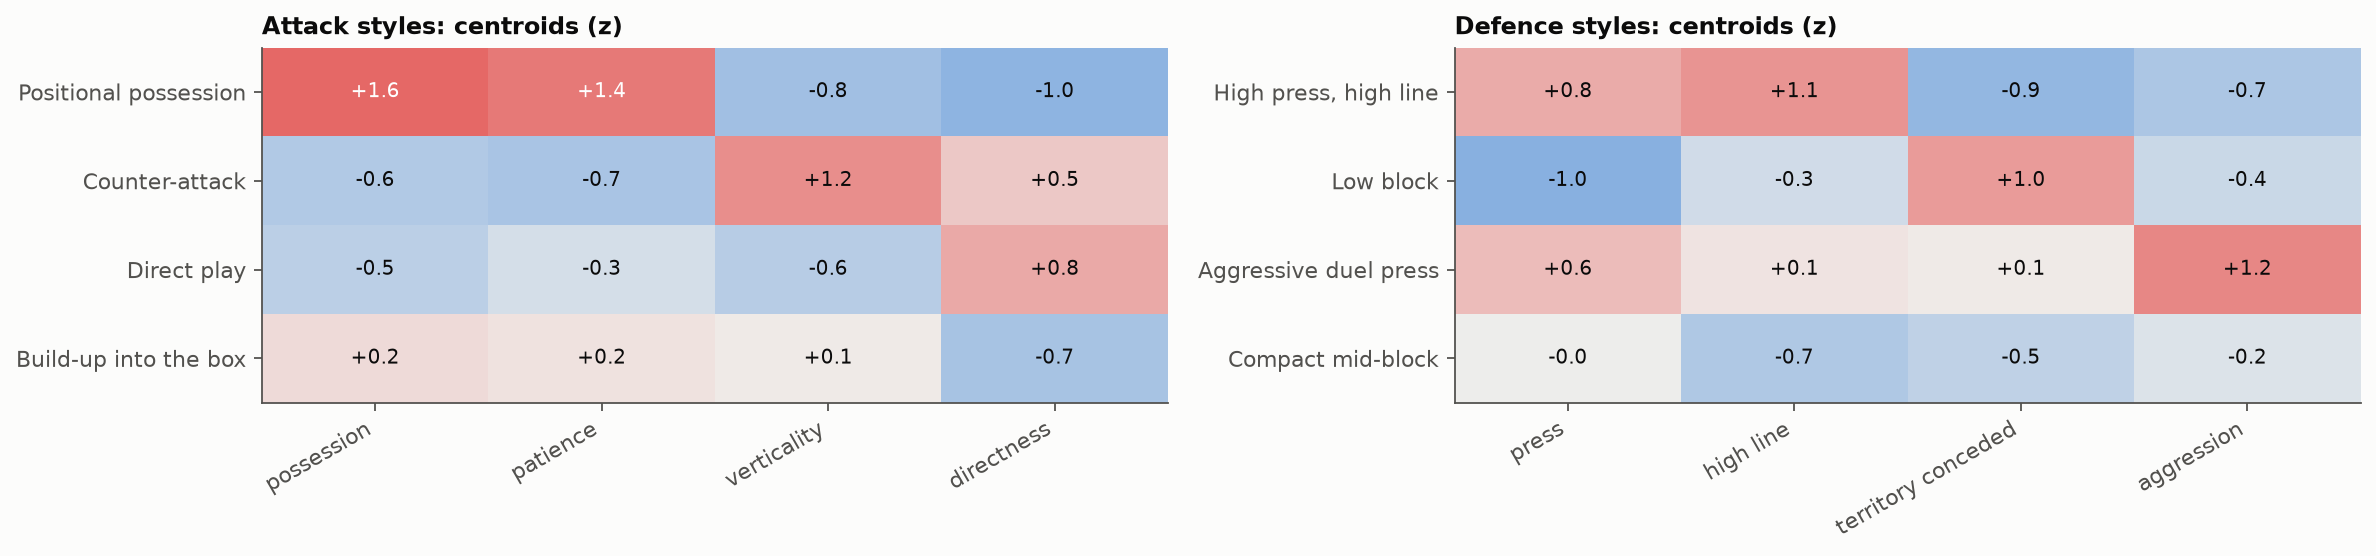

In [11]:
# Figure: centroid heatmaps per phase (rows named), side by side.
fig, axes = plt.subplots(1, 2, figsize=(15, 3.6))
for ax, ph in zip(axes, PHASES):
    cz = profiles[ph]["centroid"].rename(index=NAMES[ph]).loc[ORDER[ph]]
    ax.imshow(cz.to_numpy(), cmap=DIVERGING, vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(range(cz.shape[1]), [c.replace("_", " ") for c in cz.columns], rotation=30, ha="right")
    ax.set_yticks(range(cz.shape[0]), cz.index)
    ax.grid(False)
    for (i, j), v in np.ndenumerate(cz.to_numpy()):
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 1.3 else INK)
    ax.set_title(f"{ph.title()} styles: centroids (z)", loc="left")
fig.tight_layout()
heat_fig = save(fig, "04_centroids.png")

## Step 8. 2-D views

PCA of each phase's four dimensions, **only to draw** the clusters. Marker shapes and labels carry identity
alongside colour.

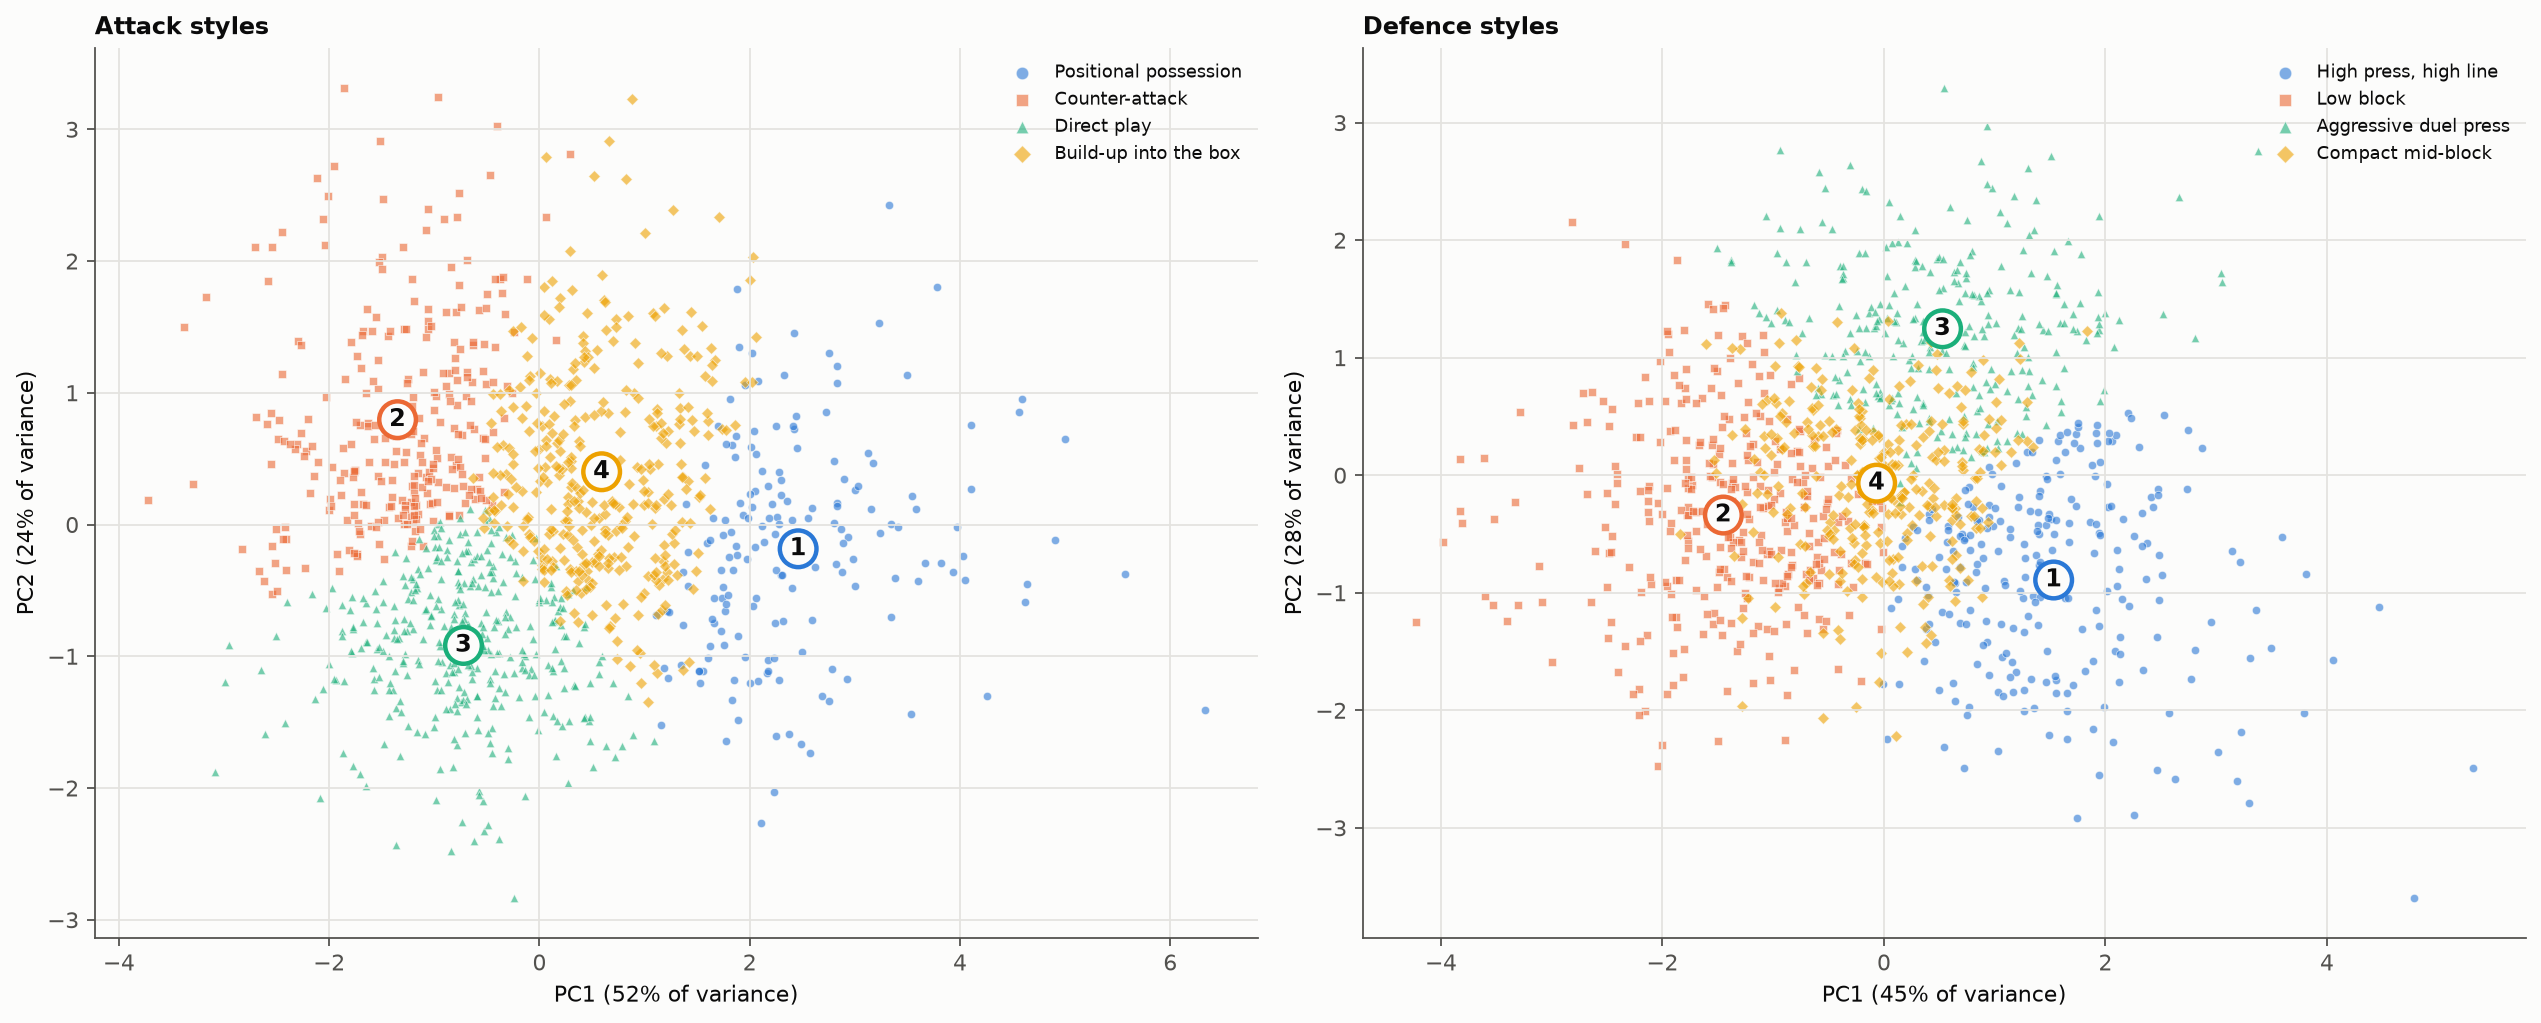

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, ph in zip(axes, PHASES):
    pca = PCA(n_components=2, random_state=SEED).fit(X[ph])
    xy, ev = pca.transform(X[ph]), pca.explained_variance_ratio_
    labels = profiles[ph]["df"].cluster.to_numpy()
    for i, name in enumerate(ORDER[ph]):
        c = next(c for c, n in NAMES[ph].items() if n == name)
        m = labels == c
        ax.scatter(xy[m, 0], xy[m, 1], s=14, color=SERIES[i], marker=MARKERS[i], alpha=0.6, edgecolors=SURFACE,
                   linewidths=0.4, label=name)
        cx, cy = xy[m].mean(axis=0)
        ax.text(cx, cy, str(i + 1), ha="center", va="center", fontsize=11, fontweight="bold", color=INK,
                bbox={"boxstyle": "circle,pad=0.25", "facecolor": SURFACE, "edgecolor": SERIES[i], "linewidth": 2})
    ax.set_xlabel(f"PC1 ({ev[0]:.0%} of variance)")
    ax.set_ylabel(f"PC2 ({ev[1]:.0%} of variance)")
    ax.set_title(f"{ph.title()} styles", loc="left")
    ax.legend(frameon=False, fontsize=8, markerscale=1.5, loc="best")
fig.tight_layout()
pca_fig = save(fig, "04_pca.png")

## Step 9. Report

In [13]:
cols = ["phase", "k", "silhouette", "davies_bouldin", "calinski_harabasz", "stability (mean ARI)", "min cluster Jaccard",
        "Ward vs K-means (ARI)", "smallest cluster", "usable"]
text = [
    "# Phase 4: Clustering",
    "",
    f"Generated {date.today().isoformat()} by `notebooks/04_clustering.ipynb`, where each step is shown with its checks.",
    "",
    "## Approach",
    "",
    "Playing style per **phase of play** (Fernandez-Navarro et al. 2016; Demir et al.): attacking style from four "
    "attacking dimensions, defensive style from four defensive dimensions, each clustered with K-means (k = 4) and "
    "checked against Ward. A team-season's style is the pair. Formation (back three) is reported, not clustered.",
    "",
    "## 1. Choosing k",
    "",
    md_table(summary[cols].round(3), index=False),
    "",
    f"![k selection](figures/{quality_fig})",
    "",
    f"![Ward dendrograms](figures/{dendro_fig})",
    "",
]
for ph in PHASES:
    p = profiles[ph]
    ctx = pd.concat([p["context"], p["examples"].rename("closest to centroid")], axis=1)
    ctx.insert(0, "style", ctx.index.map(NAMES[ph]))
    cen = p["centroid"].copy()
    cen.insert(0, "style", cen.index.map(NAMES[ph]))
    text += [f"## {2 if ph == 'attack' else 3}. {ph.title()} styles (k = {MAIN_K[ph]})", "",
             f"Share of team strength (points per match) explained: eta² = {p['eta2_points']:.2f}.", "",
             md_table(ctx.rename_axis("cluster")), "", "Centroids (z):", "", md_table(cen.round(2).rename_axis("cluster")), "",
             "League mix:", "", md_table(p["leagues"].rename(index=NAMES[ph]).rename_axis("style")), ""]
text += ["## 4. Soft memberships and consensus", "",
         "Gaussian mixture (k = 4) and consensus clustering (bootstrap K-means, bootstrap GMM and Ward) against K-means:", "",
         md_table(agreement.round(3).T.rename_axis("measure")), "",
         "Fuzzy membership of each team-season's own style (clear member: ≥ 0.5), with the GMM probability for comparison:", "",
         md_table(clarity.round(2).rename_axis(["phase", "style"])), "",
         "GMM BIC by k (lower is better):", "",
         md_table(gmm_summary.pivot(index="k", columns="phase", values="BIC").round(0).rename_axis("k")), ""]
text += ["## 5. Sensitivity clusterings (used in Phase 5 checks)", "",
         md_table(sensitivity_clusters.round(3).T.rename_axis("measure")), "",
         *[x for ph in PHASES for x in (f"{ph.capitalize()}: main style (rows) vs k = 3 cluster:", "",
           md_table(pd.crosstab(out[f"{ph}_style"], out[f"{ph}_k3_style"]).loc[ORDER[ph]].rename_axis(f"{ph} style")), "",
           f"{ph.capitalize()}: main style (rows) vs relative style:", "",
           md_table(pd.crosstab(out[f"{ph}_style"], out[f"{ph}_rel_style"]).loc[ORDER[ph], ORDER[ph]].rename_axis(f"{ph} style")), "")]]
text += ["## 6. Combined styles", "", md_table(combo.rename_axis("attack \\ defence")), "",
         md_table(combos.rename_axis("style")), "", f"![Centroids](figures/{heat_fig})", "", f"![PCA](figures/{pca_fig})", ""]
(REPORTS_DIR / "04_clustering.md").write_text("\n".join(text), encoding="utf-8")
print("wrote", REPORTS_DIR / "04_clustering.md")

wrote /Users/mohammadshweiki/Downloads/coding-projects/football-injuries/reports/04_clustering.md
